In [31]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score

In [32]:
data=pd.read_csv(r"D:\HOPEAI\ML Resources\Machine Learning-Classification\Week4.0-Machine Learning-Classification\CLassification\1.Traditional Way\Social_Network_Ads.csv")

In [33]:
data.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [76]:
data["Purchased"].value_counts()

Purchased
0    257
1    143
Name: count, dtype: int64

In [34]:
data=pd.get_dummies(data,columns=["Gender"],drop_first=True,dtype=int)

In [35]:
data.head()

,User ID,Age,EstimatedSalary,Purchased,Gender_Male
0,15624510,19,19000,0,1
1,15810944,35,20000,0,1
2,15668575,26,43000,0,0
3,15603246,27,57000,0,0
4,15804002,19,76000,0,1


In [36]:
X=data.drop(columns=["Purchased","User ID"])

In [37]:
y=data["Purchased"]

In [38]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [65]:
RF=RandomForestClassifier(n_estimators=100, criterion='entropy')
RF.fit(X_train,y_train)

,n_estimators,100
,criterion,'entropy'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [66]:
y_pred=RF.predict(X_test)
y_pred

array([1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 1, 1, 0, 0, 1, 0, 0,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       0, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 0], dtype=int64)

In [67]:
from sklearn.metrics import classification_report,confusion_matrix

report=classification_report(y_test,y_pred)
print(report)

              precision    recall  f1-score   support

           0       0.94      0.90      0.92        52
           1       0.83      0.89      0.86        28

    accuracy                           0.90        80
   macro avg       0.89      0.90      0.89        80
weighted avg       0.90      0.90      0.90        80



In [70]:
cm=confusion_matrix(y_test,y_pred)

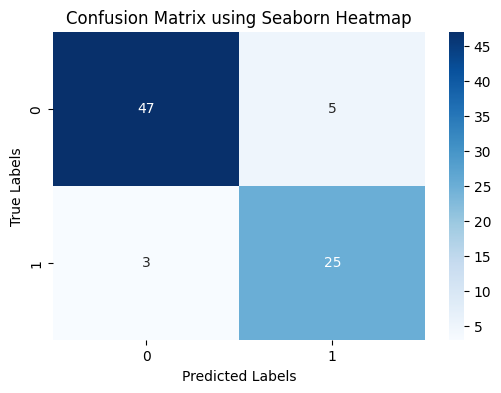

In [75]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
sns.heatmap(cm, 
    annot=True,            # Show the numbers inside the blocks
    fmt='d',               # Print numbers as integers 
    cmap='Blues',   )       # Colormap style
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix using Seaborn Heatmap')
plt.show()


In [42]:
import pickle
with open("RF_final","wb") as f:
    pickle.dump(RF,f)

In [43]:
with open("RF_final","rb") as f:
    model=pickle.load(f)

In [30]:
prediction=model.predict([[10000,136897.80,471784.10,0,1]])

C:\Users\yasod\AppData\Local\Programs\Python\Python310\lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


ValueError: X has 5 features, but RandomForestClassifier is expecting 4 features as input.

In [36]:
prediction

array([63523.79327987])